# 04 — Routine mining: the "Thursday 15:15" detector

Beyond the aggregate predictability bound, the product goal needs **specific, explainable rules**: *user X leaves place A on weekday W in time window T and goes to place B*. The miner emits **routine cards** — tuples (origin place, destination place, weekday, 15-min bucket, n_trips, support = distinct weeks seen, confidence = P(dest | origin, weekday, bucket), stability = fraction of weeks consistent) — for 76 cohort users' stop histories.

A **trigger rule** fires a suggestion when, at runtime, the user is at the card's origin on the right weekday/bucket and confidence >= threshold. `trigger_eval.parquet` replays each user's held-out trips through the rule.

**Inputs:** `routines.parquet`, `trigger_eval.parquet`.
**Outputs:** `reports/04_*.png`.

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def _find_root():
    for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (p / "data" / "processed").is_dir():
            return p
    raise RuntimeError("project root with data/processed not found")


ROOT = _find_root()
DATA = ROOT / "data" / "processed"
REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)

mpl.rcParams.update({
    "figure.figsize": (11, 4.2),
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

def save(fig, name):
    fig.savefig(REPORTS / name, dpi=150, bbox_inches="tight")
    print(f"saved reports/{name}")

WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]


In [2]:
r = pd.read_parquet(DATA / "routines.parquet")
te = pd.read_parquet(DATA / "trigger_eval.parquet")

print(f"routine cards: {len(r)} across {r['user'].nunique()} users "
      f"of {len(pd.read_parquet(DATA / 'cohort.parquet'))} cohort users")
print(f"weekday distribution: {r['weekday'].map(dict(enumerate(WEEKDAYS))).value_counts().to_dict()}")
print(f"support   : median {r['support'].median()}, mean {r['support'].mean():.2f}, max {r['support'].max()}")
print(f"confidence: median {r['confidence'].median():.2f}")
print(f"stability : median {r['stability'].median():.2f}")

routine cards: 244 across 34 users of 76 cohort users
weekday distribution: {'Mon': 42, 'Sat': 42, 'Tue': 39, 'Thu': 33, 'Fri': 30, 'Sun': 30, 'Wed': 28}
support   : median 3.0, mean 3.46, max 8
confidence: median 1.00
stability : median 1.00


## 1. When do routines live? Weekday x hour heatmap

Cards by weekday and hour-of-day (each 15-min bucket mapped to its hour).

saved reports/04_weekday_bucket.png


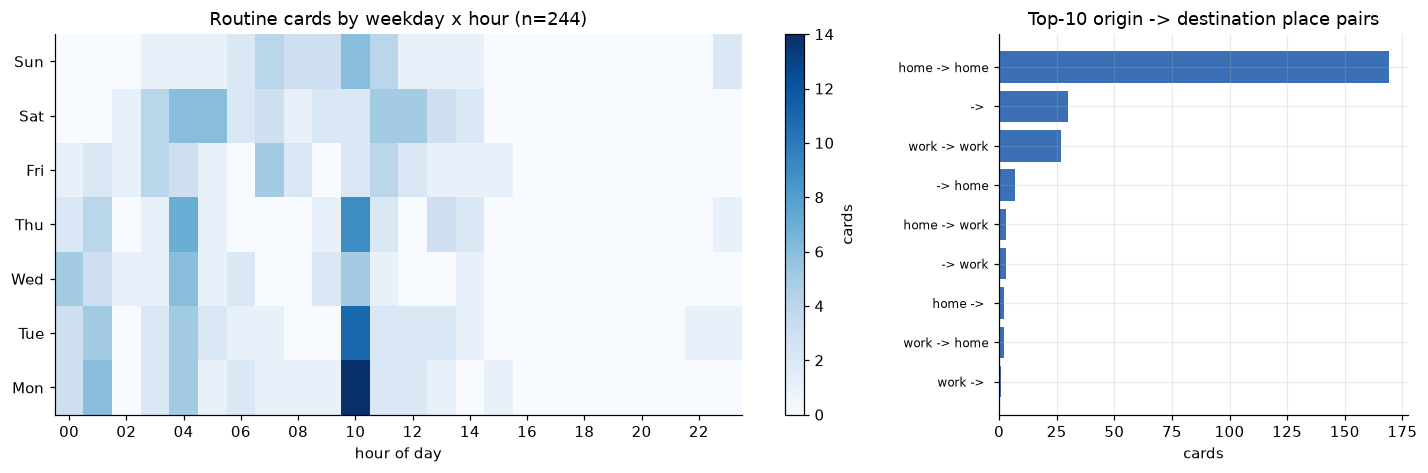

cards with home as origin or destination: 75.0% of all cards


In [3]:
r = r.assign(hour=r["bucket"] // 4)
heat = (r.groupby(["weekday", "hour"]).size().unstack(fill_value=0)
          .reindex(index=range(7), columns=range(24), fill_value=0))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [2.1, 1]})

im = axes[0].imshow(heat.values, aspect="auto", cmap="Blues", origin="lower")
fig.colorbar(im, ax=axes[0], label="cards")
axes[0].set_xticks(range(0, 24, 2), [f"{h:02d}" for h in range(0, 24, 2)])
axes[0].set_yticks(range(7), WEEKDAYS)
axes[0].set_xlabel("hour of day")
axes[0].set_title(f"Routine cards by weekday x hour (n={len(r)})")
axes[0].grid(False)

pairs = r["o_label"].str.replace("_", " ", regex=False) + " -> " + r["d_label"]
top_pairs = pairs.value_counts().head(10)[::-1]
axes[1].barh(top_pairs.index, top_pairs.values, color="#3b6fb6")
axes[1].set_xlabel("cards")
axes[1].set_title("Top-10 origin -> destination place pairs")
axes[1].tick_params(axis="y", labelsize=8)

fig.tight_layout()
save(fig, "04_weekday_bucket.png")
plt.show()

print("cards with home as origin or destination: "
      f"{(pairs.str.contains('home')).mean():.1%} of all cards")

The mass sits in the **early-morning hours (roughly 00:00-08:00)** and the pairs are dominated by **home -> home** cards — 75.0% of all cards involve home as origin or destination. That is expected from stop-to-stop transitions (a night at home = many midnight/early-morning departures to home itself) and is the main caveat of the current card set: genuinely *commute-like* routines (work, school, gym) are a minority, and weeknight-vs-weekend differences are mild (28-42 cards per weekday).

The strongest card overall is user **153, Tuesday 10:15-10:30, home -> home, support 8 weeks, confidence 1.00** — a weekly mid-morning at-home block, not a commute. Useful, but a product should not call it "driving to music school".

## 2. Card quality: support, confidence, stability

Support is capped by construction (need >= 3 distinct weeks), so the distribution piles up at the floor; confidence and stability are high where cards exist at all — the miner only emits strong patterns.

saved reports/04_support_confidence.png


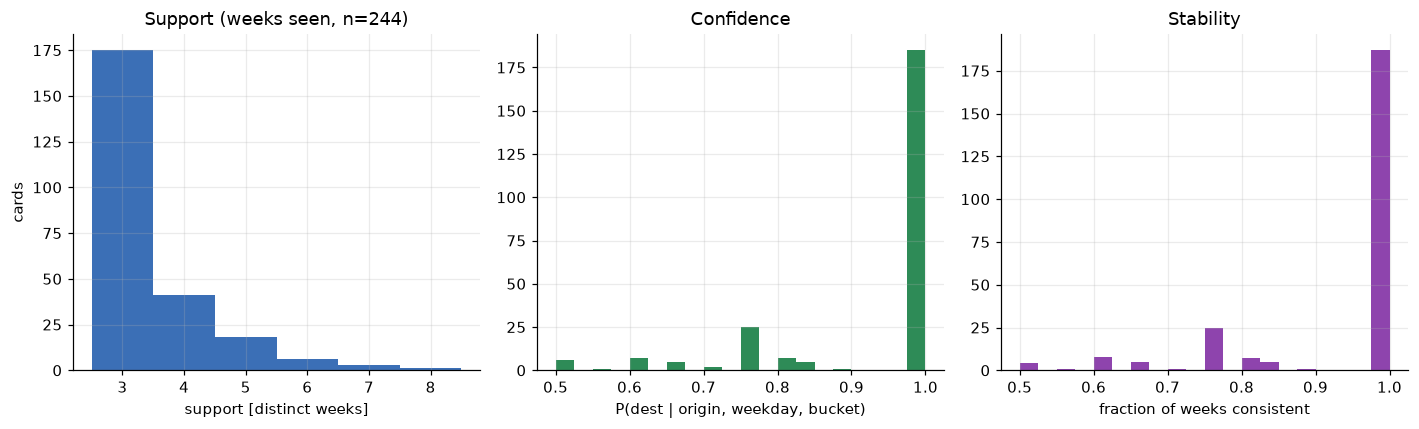

cards with confidence==1.0: 75.8%
cards with support>=5    : 28


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].hist(r["support"], bins=np.arange(2.5, r["support"].max() + 1.5), color="#3b6fb6")
axes[0].set_title(f"Support (weeks seen, n={len(r)})")
axes[0].set_xlabel("support [distinct weeks]")
axes[0].set_ylabel("cards")

axes[1].hist(r["confidence"], bins=20, color="#2e8b57")
axes[1].set_title("Confidence")
axes[1].set_xlabel("P(dest | origin, weekday, bucket)")

axes[2].hist(r["stability"], bins=20, color="#8e44ad")
axes[2].set_title("Stability")
axes[2].set_xlabel("fraction of weeks consistent")

fig.tight_layout()
save(fig, "04_support_confidence.png")
plt.show()

print(f"cards with confidence==1.0: {(r['confidence'] == 1.0).mean():.1%}")
print(f"cards with support>=5    : {(r['support'] >= 5).sum()}")

## 3. Strongest cards

Top-10 by support (ties broken by confidence):

In [5]:
top10 = (r.sort_values(["support", "confidence"], ascending=False).head(10)
           .assign(route=lambda d: d["o_label"] + " -> " + d["d_label"],
                   day=lambda d: d["weekday"].map(dict(enumerate(WEEKDAYS))))
           [["user", "day", "bucket_str", "route", "support", "confidence", "stability"]]
           .reset_index(drop=True))
top10

,user,day,bucket_str,route,support,confidence,stability
0,153,Tue,10:15-10:30,home -> home,8,1.000000,1.000000
1,012,Wed,03:30-03:45,home -> home,7,1.000000,1.000000
2,153,Mon,00:00-00:15,home -> home,7,1.000000,1.000000
3,004,Fri,03:45-04:00,home -> home,7,0.875000,0.875000
4,002,Thu,04:00-04:15,home -> home,6,1.000000,1.000000
5,003,Mon,10:15-10:30,home -> home,6,1.000000,1.000000
6,004,Thu,04:45-05:00,home -> home,6,1.000000,1.000000
7,003,Tue,04:15-04:30,home -> home,6,0.750000,0.750000
8,128,Tue,01:15-01:30,home -> home,6,0.666667,0.666667
9,128,Thu,01:30-01:45,home -> home,6,0.600000,0.600000


All ten are home-anchored, mostly night hours — again the overnight-stay signature. Confidence 1.0 means the destination was never different under the same (origin, weekday, bucket) context; with support 5-8 weeks that is genuinely strong, but it is regularity of *staying*, not of *travelling*.

## 4. Trigger evaluation: precision & recall

Replaying held-out trips: a trigger is **eligible** when the user is at a card origin in the right weekday/bucket; it **fires** if confidence >= threshold; a **hit** is a fired trigger whose actual destination matches the card.

saved reports/04_trigger_eval.png


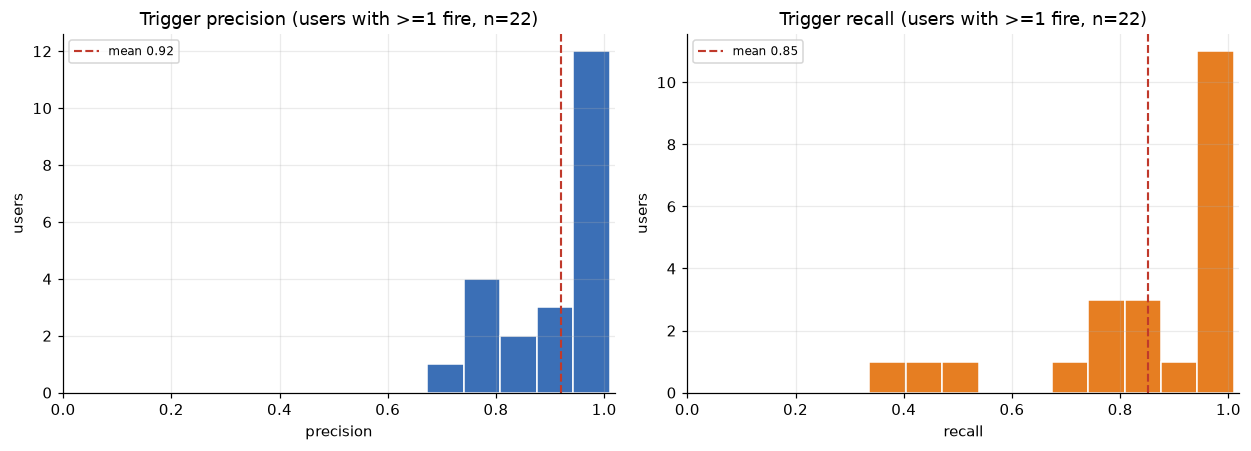

users evaluated: 176; fired >=1 trigger: 22; never fired: 154
macro precision (firing users): 0.920  (median 0.983)
macro recall    (firing users): 0.851  (median 0.928)
micro precision: 170/190 = 0.895
micro recall   : 170/228 = 0.746


In [6]:
fired = te[te["n_fired"] > 0]
n_zero = int((te["n_fired"] == 0).sum())
micro_p = te["n_hits"].sum() / te["n_fired"].sum()
micro_r = te["n_hits"].sum() / te["n_eligible"].sum()

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
for ax, col, colr in [(axes[0], "precision", "#3b6fb6"), (axes[1], "recall", "#e67e22")]:
    ax.hist(fired[col], bins=np.linspace(0, 1.01, 16), color=colr, edgecolor="white")
    ax.axvline(fired[col].mean(), color="#c0392b", ls="--", lw=1.4,
               label=f"mean {fired[col].mean():.2f}")
    ax.set_xlabel(col)
    ax.set_ylabel("users")
    ax.set_title(f"Trigger {col} (users with >=1 fire, n={len(fired)})")
    ax.set_xlim(0, 1.02)
    ax.legend(fontsize=8)

fig.tight_layout()
save(fig, "04_trigger_eval.png")
plt.show()

print(f"users evaluated: {len(te)}; fired >=1 trigger: {len(fired)}; never fired: {n_zero}")
print(f"macro precision (firing users): {fired['precision'].mean():.3f}  "
      f"(median {fired['precision'].median():.3f})")
print(f"macro recall    (firing users): {fired['recall'].mean():.3f}  "
      f"(median {fired['recall'].median():.3f})")
print(f"micro precision: {te['n_hits'].sum()}/{te['n_fired'].sum()} = {micro_p:.3f}")
print(f"micro recall   : {te['n_hits'].sum()}/{te['n_eligible'].sum()} = {micro_r:.3f}")

## Takeaways & caveats

- **Precision is high — micro 0.895** (170 hits / 190 fires; macro mean 0.92, median 0.98 over the 22 users who ever fire). When a routine card fires, it is right ~9 times in 10.
- **Recall is lower — micro 0.746** (170 / 228 eligible opportunities; macro mean 0.85 among firing users), and crucially **154 of 176 users never fire at all**: the card set covers only 34 users, so most users get no proactive suggestions under the current thresholds.
- **Proactive-suggestion framing.** High precision / modest coverage is the right operating point for suggestions: a wrong ping destroys trust, a missing one is invisible. The lever is *coverage* (more cards per user), not precision.
- **Caveats:** cards are dominated by overnight home->home regularities (so trigger eligibility often means "it's night and the user is home"); support is capped low (median 3 weeks) making confidence estimates fragile; the 22 firing users are self-selected (users with many repeated weeks); the confidence threshold trades precision for recall directly — the reported numbers are one point on that curve, not a tuned optimum.